In [1]:
# Predicting intimate partner violence prevalence in East and Central Africa
# Run each "# %%" section as a cell in VS Code (click "Run Cell"), or run the whole file.

# Predicting Intimate Partner Violence Prevalence in East and Central Africa

**Mission:** Reduce gender-based violence by letting people report incidents anonymously, with every report followed up by the Isange One Stop Centre and the Rwanda Investigation Bureau (RIB).

**Use case:** Predict the percentage of women in a group (country, survey year, age band, education level, wealth, residence and so on) who experienced physical and/or sexual violence from a husband or partner in the last 12 months.

**Who uses it and for what:** Isange One Stop Centre, RIB and the reporting platform's team can use the predicted percentage to decide where to put outreach, awareness campaigns and follow-up staff first, so reports coming from higher-risk groups get faster attention.

**Target variable:** `violence_pct` (a continuous percentage, 0-100).

## 1. Dataset

- **Source:** Demographic and Health Surveys (DHS) Program, downloaded through the free DHS API (https://api.dhsprogram.com). Indicator used for the target: `DV_SPV1_W_PAS`, physical and sexual violence committed by husband/partner in the last 12 months.
- **How it was built:** `build_dataset.py` downloads the target broken down by country, survey year and group, then adds national context indicators for the same survey (women's literacy, secondary education, bank account, acceptance of wife beating, fertility rate).
- **Scope:** Rwanda has only 245 rows, which is not enough for a reliable model. We therefore train on 10 East and Central African countries, so Rwanda can be compared with countries in similar contexts. Country remains an input, so the model can still predict for Rwanda.

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import SGDRegressor, LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
TARGET = "violence_pct"
COUNTRIES = ["Rwanda", "Burundi", "Uganda", "Kenya", "Tanzania",
             "Congo Democratic Republic", "Ethiopia", "Zambia", "Malawi", "Mozambique"]

In [3]:
df = pd.read_csv("violence_dataset.csv")
print("All countries:", df.shape)

# Keep East and Central Africa, and drop national-total rows (they repeat information
# that the group rows already contain).
df = df[df["CountryName"].isin(COUNTRIES)]
df = df[~df["CharacteristicCategory"].str.startswith("Total")]
df = df.drop_duplicates().reset_index(drop=True)

print("East and Central Africa:", df.shape)
print("Rows >= 1000:", len(df) >= 1000)
df.head()

All countries: (6026, 13)
East and Central Africa: (1582, 13)
Rows >= 1000: True


,CountryName,SurveyYear,CharacteristicCategory,CharacteristicLabel,DenominatorWeighted,violence_pct,women_literate_pct,women_secondary_edu_pct,women_employed_pct,women_mobile_phone_pct,women_bank_account_pct,women_accept_wife_beating_pct,total_fertility_rate
0,Burundi,2016,Age (5-year groups),15-19,152,13.2,67.9,22.5,14.5,NaN,5.4,61.8,5.5
1,Burundi,2016,Age (5-year groups),20-24,994,10.6,67.9,22.5,14.5,NaN,5.4,61.8,5.5
2,Burundi,2016,Age (5-year groups),25-29,1421,9.6,67.9,22.5,14.5,NaN,5.4,61.8,5.5
3,Burundi,2016,Age (5-year groups),30-34,1365,8.4,67.9,22.5,14.5,NaN,5.4,61.8,5.5
4,Burundi,2016,Age (5-year groups),35-39,1084,6.7,67.9,22.5,14.5,NaN,5.4,61.8,5.5


In [4]:
df.info()
print()
print("Missing values per column:")
print(df.isna().sum())
df.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 1582 entries, 0 to 1581
Data columns (total 13 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   CountryName                    1582 non-null   str    
 1   SurveyYear                     1582 non-null   int64  
 2   CharacteristicCategory         1582 non-null   str    
 3   CharacteristicLabel            1582 non-null   str    
 4   DenominatorWeighted            1582 non-null   int64  
 5   violence_pct                   1582 non-null   float64
 6   women_literate_pct             1542 non-null   float64
 7   women_secondary_edu_pct        1582 non-null   float64
 8   women_employed_pct             1468 non-null   float64
 9   women_mobile_phone_pct         719 non-null    float64
 10  women_bank_account_pct         909 non-null    float64
 11  women_accept_wife_beating_pct  1582 non-null   float64
 12  total_fertility_rate           1582 non-null   float64
dtyp

,count,mean,std,min,25%,50%,75%,max
SurveyYear,1582.0,2016.213021,6.720366,2003.0,2011.00,2016.0,2022.00,2025.0
DenominatorWeighted,1582.0,1563.703540,1560.850652,20.0,571.25,1084.0,2032.75,12796.0
violence_pct,1582.0,7.249305,4.646994,0.0,4.40,6.3,8.60,35.2
women_literate_pct,1542.0,69.293580,13.085617,40.2,59.10,69.7,79.80,90.9
women_secondary_edu_pct,1582.0,20.129836,8.662799,6.9,13.60,18.2,24.30,40.3
women_employed_pct,1468.0,18.119755,10.568077,5.1,10.80,14.4,19.20,41.5
women_mobile_phone_pct,719.0,4.740334,12.075888,0.2,0.80,1.2,3.70,54.1
women_bank_account_pct,909.0,16.077778,10.736770,2.9,7.30,11.7,28.50,35.7
women_accept_wife_beating_pct,1582.0,43.718963,17.765473,12.6,29.60,47.8,56.20,75.6
total_fertility_rate,1582.0,4.899052,0.921707,3.4,4.00,4.9,5.50,6.7


## 2. Explore the data

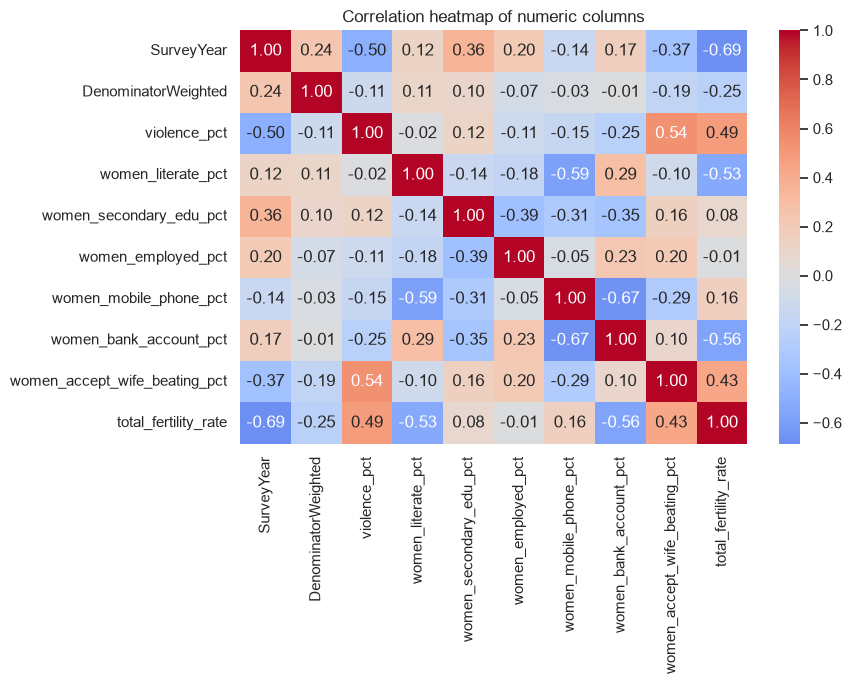

Correlation with the target (strongest first):
women_accept_wife_beating_pct    0.543
SurveyYear                      -0.499
total_fertility_rate             0.490
women_bank_account_pct          -0.245
women_mobile_phone_pct          -0.154
women_secondary_edu_pct          0.124
DenominatorWeighted             -0.114
women_employed_pct              -0.107
women_literate_pct              -0.021
Name: violence_pct, dtype: float64


In [5]:
numeric_cols = df.select_dtypes(include="number").columns.tolist()

plt.figure(figsize=(9, 7))
sns.heatmap(df[numeric_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap of numeric columns")
plt.tight_layout()
plt.show()

corr_target = df[numeric_cols].corr()[TARGET].drop(TARGET).sort_values(key=abs, ascending=False)
print("Correlation with the target (strongest first):")
print(corr_target.round(3))

**What the heatmap shows:** how strongly each numeric column moves with `violence_pct` and with the other columns. The printed list under the plot ranks the columns by their link to the target.

**What we decided:** we keep the columns with a clear link to the target and rely on scaling and regularization for columns that are strongly correlated with each other (the national indicators such as literacy, secondary education and fertility describe similar things). We also use the strongest-correlated feature for the scatter plots in section 6. *(Edit this text to match the numbers you see in your own heatmap.)*

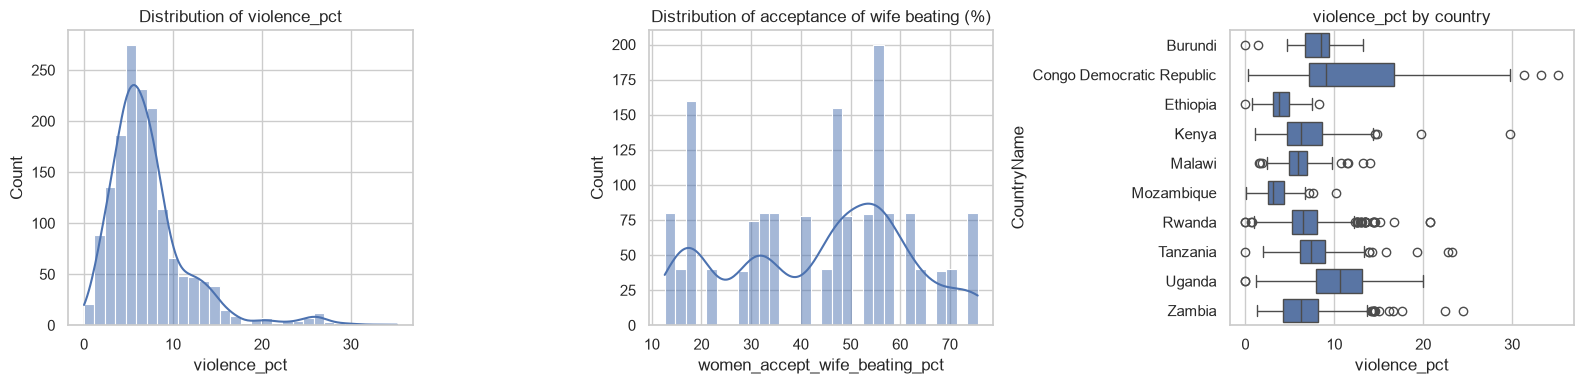

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.histplot(df[TARGET], bins=30, kde=True, ax=axes[0])
axes[0].set_title("Distribution of violence_pct")

sns.histplot(df["women_accept_wife_beating_pct"], bins=30, kde=True, ax=axes[1])
axes[1].set_title("Distribution of acceptance of wife beating (%)")

sns.boxplot(data=df, y="CountryName", x=TARGET, ax=axes[2])
axes[2].set_title("violence_pct by country")

plt.tight_layout()
plt.show()

**What the plots show:** the left histogram shows how the target is spread across groups. The middle histogram shows the spread of one national attitude indicator. The boxplot compares the target across countries.

**What we decided:** because violence levels differ clearly between countries, `CountryName` is kept as an input and one-hot encoded. If the target is skewed, we keep it as it is, because MSE on the original percentage scale is easy to explain to Isange and RIB. *(Edit this text to match your own plots.)*

## 3. Feature engineering

In [7]:
print("Columns:", df.columns.tolist())

# Columns we drop, and why
DROP_COLS = [
    "DenominatorWeighted",             # size of the survey sample for that group, not a driver of violence, and a user could not know it
    "women_employed_pct",              # matched only one type of employment (e.g. employed by a family member), so it is misleading
    "women_mobile_phone_pct",          # matched 'mobile clinic' indicators, not phone ownership
    "women_median_age_first_marriage", # too many missing values
]
df = df.drop(columns=[c for c in DROP_COLS if c in df.columns])

X = df.drop(columns=[TARGET])
y = df[TARGET]

numeric_features = X.select_dtypes(include="number").columns.tolist()
categorical_features = X.select_dtypes(exclude="number").columns.tolist()
print("Features:", X.columns.tolist())
print("Numeric:", numeric_features)
print("Categorical:", categorical_features)
print("Number of feature columns:", X.shape[1], "(need at least 8)")

Columns: ['CountryName', 'SurveyYear', 'CharacteristicCategory', 'CharacteristicLabel', 'DenominatorWeighted', 'violence_pct', 'women_literate_pct', 'women_secondary_edu_pct', 'women_employed_pct', 'women_mobile_phone_pct', 'women_bank_account_pct', 'women_accept_wife_beating_pct', 'total_fertility_rate']
Features: ['CountryName', 'SurveyYear', 'CharacteristicCategory', 'CharacteristicLabel', 'women_literate_pct', 'women_secondary_edu_pct', 'women_bank_account_pct', 'women_accept_wife_beating_pct', 'total_fertility_rate']
Numeric: ['SurveyYear', 'women_literate_pct', 'women_secondary_edu_pct', 'women_bank_account_pct', 'women_accept_wife_beating_pct', 'total_fertility_rate']
Categorical: ['CountryName', 'CharacteristicCategory', 'CharacteristicLabel']
Number of feature columns: 9 (need at least 8)


**Dropped columns and why:**
- `DenominatorWeighted`: the size of the survey sample for a group. It is not a driver of violence and a person using the app would not know it.
- `women_employed_pct`: it matched a single type of employment (such as employed by a family member), so it does not measure employment overall.
- `women_mobile_phone_pct`: it matched indicators about mobile clinics, not phone ownership.
- `women_median_age_first_marriage`: too many missing values (dropped automatically by `build_dataset.py`).

**Categorical to numeric:** `CountryName`, `CharacteristicCategory` and `CharacteristicLabel` are one-hot encoded in the preprocessing step below.

## 4. Split and standardize

The data is split 80% train and 20% test. The scaler, the imputer for missing values and the one-hot encoder are all **fitted on the training set only**, then applied to the test set, so no test information leaks into the model.

Note: national indicators repeat for every group in the same survey, so rows from one survey can land in both train and test. This makes the test score slightly optimistic compared with predicting for a brand-new survey.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

numeric_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])
categorical_pipe = Pipeline([
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])
preprocessor = ColumnTransformer([
    ("num", numeric_pipe, numeric_features),
    ("cat", categorical_pipe, categorical_features),
])

# Fit on the training set only
Xtr = preprocessor.fit_transform(X_train)
Xte = preprocessor.transform(X_test)
ytr = y_train.to_numpy()
yte = y_test.to_numpy()

print("Train:", Xtr.shape, "Test:", Xte.shape)
print("Mean of scaled numeric columns on train (should be ~0):",
      Xtr[:, :len(numeric_features)].mean(axis=0).round(2))

Train: (1265, 71) Test: (317, 71)
Mean of scaled numeric columns on train (should be ~0): [-0. -0.  0.  0.  0.  0.]


## 5. Train and compare four models

All four models are evaluated on the same test set with mean squared error (MSE).

### 5.1 SGDRegressor (linear regression by gradient descent)

scikit-learn does not record the loss per epoch, so we train with `partial_fit` in a loop and store the train and test MSE after every epoch. To tune it honestly, we try different learning rates and regularization strengths on a **validation set taken from the training data**, and keep the test set for the final comparison.

In [9]:
def mse(y_true, y_pred):
    with np.errstate(all="ignore"):
        val = float(np.mean((y_true - y_pred) ** 2))
    return val if np.isfinite(val) else np.inf


def run_sgd(Xa, ya, Xb, yb, eta0, alpha, epochs, seed=RANDOM_STATE):
    """Train with partial_fit and record train/eval MSE after each epoch."""
    rng = np.random.RandomState(seed)
    model = SGDRegressor(loss="squared_error", penalty="l2", alpha=alpha,
                         learning_rate="constant", eta0=eta0, random_state=seed)
    train_losses, eval_losses = [], []
    for _ in range(epochs):
        idx = rng.permutation(len(Xa))
        with np.errstate(all="ignore"):
            model.partial_fit(Xa[idx], ya[idx])
        train_losses.append(mse(ya, model.predict(Xa)))
        eval_losses.append(mse(yb, model.predict(Xb)))
    return model, train_losses, eval_losses


# Validation split taken from the training data only
Xfit, Xval, yfit, yval = train_test_split(Xtr, ytr, test_size=0.2, random_state=RANDOM_STATE)

EPOCHS = 100
etas = [0.0005, 0.005, 0.01, 0.05]
alphas = [1e-5, 1e-3, 1e-1, 1.0]

rows = []
for eta0 in etas:
    for alpha in alphas:
        _, _, val_curve = run_sgd(Xfit, yfit, Xval, yval, eta0, alpha, EPOCHS)
        rows.append({"learning_rate": eta0, "alpha": alpha,
                     "val_MSE_epoch10": val_curve[9],
                     "val_MSE_epoch50": val_curve[49],
                     "val_MSE_epoch100": val_curve[-1]})

tuning = pd.DataFrame(rows).sort_values("val_MSE_epoch100").reset_index(drop=True)
tuning

,learning_rate,alpha,val_MSE_epoch10,val_MSE_epoch50,val_MSE_epoch100
0,0.0050,0.00001,8.803171,8.414363,8.509260
1,0.0050,0.00100,8.825166,8.415040,8.528611
2,0.0100,0.00001,8.604712,8.657762,8.635537
3,0.0005,0.00001,10.446078,9.141961,8.675991
4,0.0005,0.00100,10.448048,9.155568,8.696930
5,0.0100,0.00100,8.625706,8.689105,8.710471
6,0.0005,0.10000,10.674753,10.192881,10.218213
7,0.0500,0.00001,9.508298,11.961650,10.390109
8,0.0500,0.00100,9.544214,12.097432,10.695912
9,0.0050,0.10000,10.425607,10.356787,10.883704


In [10]:
best = tuning.iloc[0]
best_eta0, best_alpha = float(best["learning_rate"]), float(best["alpha"])
print(f"Best learning rate: {best_eta0}, best alpha: {best_alpha}")

# Effect of each hyperparameter on validation MSE (epoch 100)
print("\nAverage validation MSE by learning rate:")
print(tuning.groupby("learning_rate")["val_MSE_epoch100"].mean().round(2))
print("\nAverage validation MSE by alpha (regularization):")
print(tuning.groupby("alpha")["val_MSE_epoch100"].mean().round(2))
print("\nAverage validation MSE by number of epochs:")
print(tuning[["val_MSE_epoch10", "val_MSE_epoch50", "val_MSE_epoch100"]].replace(np.inf, np.nan).mean().round(2))

Best learning rate: 0.005, best alpha: 1e-05

Average validation MSE by learning rate:
learning_rate
0.0005    10.15
0.0050    10.52
0.0100    10.87
0.0500    13.19
Name: val_MSE_epoch100, dtype: float64

Average validation MSE by alpha (regularization):
alpha
0.00001     9.05
0.00100     9.16
0.10000    11.74
1.00000    14.78
Name: val_MSE_epoch100, dtype: float64

Average validation MSE by number of epochs:
val_MSE_epoch10     10.82
val_MSE_epoch50     11.50
val_MSE_epoch100    11.18
dtype: float64


**What we learned from tuning:** the first table shows validation MSE for every learning rate and regularization strength, and the three printed summaries show how each hyperparameter changes the loss on average (a very small learning rate learns too slowly, a very large one can make the loss unstable, strong regularization can underfit, and more epochs generally lower the loss until it levels off). *(Edit this text with the numbers from your own run, because you need them for video question 2.)*

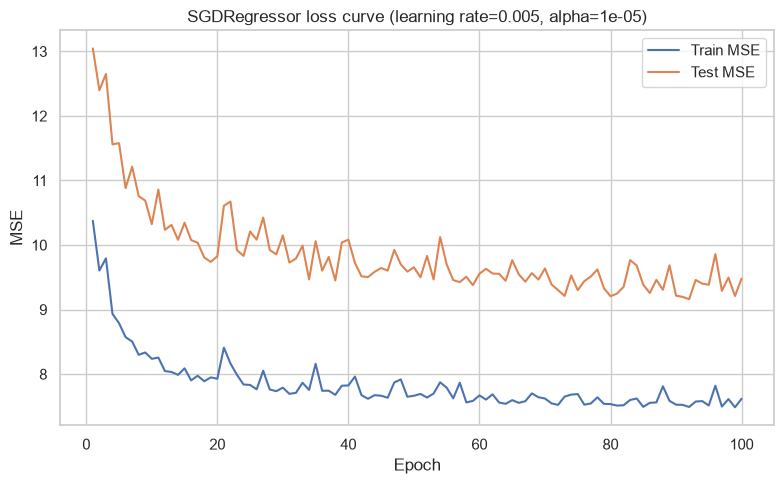

In [11]:
# Final SGD model: best settings, trained on the full training set
sgd, sgd_train_curve, sgd_test_curve = run_sgd(Xtr, ytr, Xte, yte, best_eta0, best_alpha, EPOCHS)

plt.figure(figsize=(8, 5))
plt.plot(range(1, EPOCHS + 1), sgd_train_curve, label="Train MSE")
plt.plot(range(1, EPOCHS + 1), sgd_test_curve, label="Test MSE")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title(f"SGDRegressor loss curve (learning rate={best_eta0}, alpha={best_alpha})")
plt.legend()
plt.tight_layout()
plt.show()

**What the loss curve shows:** train and test MSE after each epoch. Both should fall quickly and then level off. If the test curve stays close to the train curve, the model is not overfitting; a large gap would mean it is memorizing the training data. *(Edit this text to match your own curve.)*

### 5.2 The other three models

In [12]:
lin = LinearRegression().fit(Xtr, ytr)

tree = DecisionTreeRegressor(max_depth=10, min_samples_leaf=3, random_state=RANDOM_STATE).fit(Xtr, ytr)

forest = RandomForestRegressor(n_estimators=200, min_samples_leaf=2,
                               random_state=RANDOM_STATE, n_jobs=-1).fit(Xtr, ytr)

models = {
    "SGDRegressor": sgd,
    "LinearRegression": lin,
    "DecisionTreeRegressor": tree,
    "RandomForestRegressor": forest,
}

results = pd.DataFrame({
    name: {"Train MSE": mse(ytr, m.predict(Xtr)), "Test MSE": mse(yte, m.predict(Xte))}
    for name, m in models.items()
}).T.round(3)

results

,Train MSE,Test MSE
SGDRegressor,7.618,9.479
LinearRegression,7.417,9.066
DecisionTreeRegressor,3.954,6.324
RandomForestRegressor,2.383,6.030


In [13]:
best_name = results["Test MSE"].idxmin()
print(f"Best model (lowest test MSE): {best_name}  ->  test MSE = {results.loc[best_name, 'Test MSE']}")

Best model (lowest test MSE): RandomForestRegressor  ->  test MSE = 6.03


**Best model:** the model with the lowest test MSE in the table above, as printed in the cell above. We choose by test MSE because it measures error on rows the model has never seen. *(After you run the notebook, add one or two sentences explaining why this model suits the dataset, for example: it has a mix of numeric and categorical columns, strong interactions between country and group, and a few hundred to a few thousand rows.)*

## 6. Required scatter plots

Feature most correlated with the target: women_accept_wife_beating_pct | r = 0.543


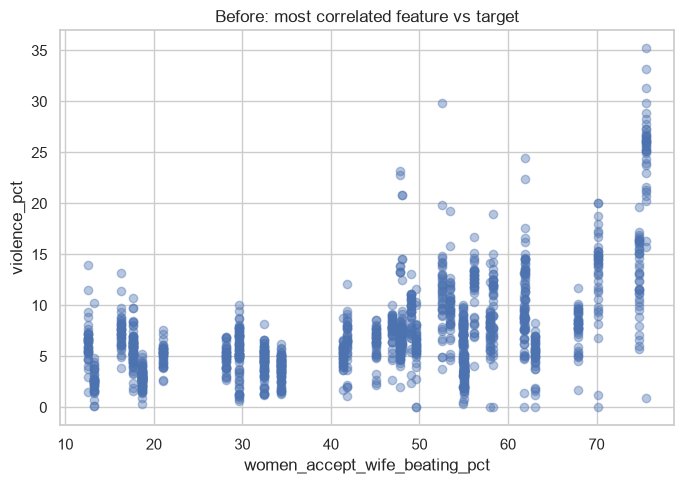

In [14]:
top_feature = corr_target.abs().idxmax()
print("Feature most correlated with the target:", top_feature, "| r =", round(corr_target[top_feature], 3))

# Before: scatter only
plt.figure(figsize=(7, 5))
plt.scatter(df[top_feature], df[TARGET], alpha=0.4)
plt.xlabel(top_feature)
plt.ylabel(TARGET)
plt.title("Before: most correlated feature vs target")
plt.tight_layout()
plt.show()

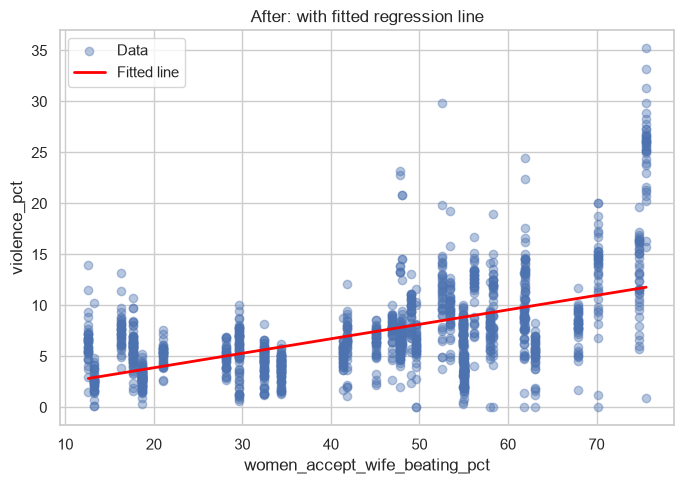

Slope: 0.142 | Intercept: 1.04


In [15]:
# After: same scatter with a one-feature linear regression line (for this plot only)
sub = df[[top_feature, TARGET]].dropna()
line = LinearRegression().fit(sub[[top_feature]], sub[TARGET])
xs = np.linspace(sub[top_feature].min(), sub[top_feature].max(), 100).reshape(-1, 1)

plt.figure(figsize=(7, 5))
plt.scatter(sub[top_feature], sub[TARGET], alpha=0.4, label="Data")
plt.plot(xs, line.predict(pd.DataFrame(xs, columns=[top_feature])), color="red", linewidth=2, label="Fitted line")
plt.xlabel(top_feature)
plt.ylabel(TARGET)
plt.title("After: with fitted regression line")
plt.legend()
plt.tight_layout()
plt.show()
print("Slope:", round(line.coef_[0], 3), "| Intercept:", round(line.intercept_, 3))

## 7. Which features matter most

Permutation importance on the test set: how much the test error rises when one original column is shuffled.

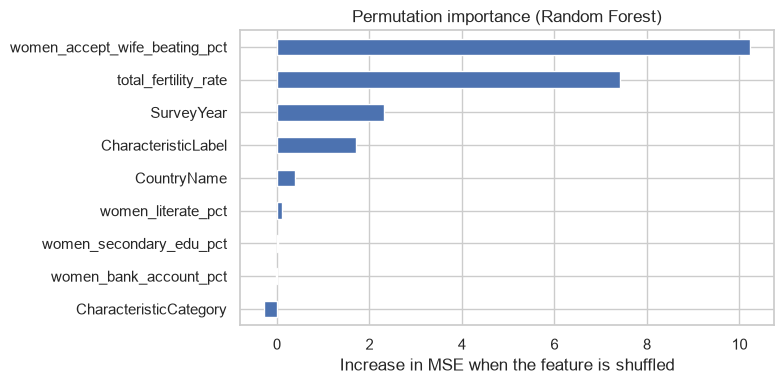

women_accept_wife_beating_pct    10.222
total_fertility_rate              7.414
SurveyYear                        2.310
CharacteristicLabel               1.714
CountryName                       0.398
women_literate_pct                0.110
women_secondary_edu_pct           0.031
women_bank_account_pct           -0.026
CharacteristicCategory           -0.269
dtype: float64

In [16]:
rf_pipeline = Pipeline([("prep", preprocessor), ("model", forest)])
imp = permutation_importance(rf_pipeline, X_test, y_test, n_repeats=5,
                             random_state=RANDOM_STATE, scoring="neg_mean_squared_error")
importance = pd.Series(imp.importances_mean, index=X_test.columns).sort_values(ascending=False)

importance.plot(kind="barh", figsize=(8, 4)).invert_yaxis()
plt.title("Permutation importance (Random Forest)")
plt.xlabel("Increase in MSE when the feature is shuffled")
plt.tight_layout()
plt.show()
importance.round(3)

**Most important features:** the columns at the top of the bar chart. They are the ones the model relies on most to predict `violence_pct`. *(Name the top three in your own words after you run it.)*

## 8. Save the best model with its preprocessing

The preprocessing (imputer, scaler, one-hot encoder) is saved together with the best model as one scikit-learn `Pipeline`, so the API can send raw input values straight to it.

In [17]:
fitted = {name: Pipeline([("prep", preprocessor), ("model", m)]) for name, m in models.items()}
best_pipeline = fitted[best_name]

os.makedirs("../API", exist_ok=True)
joblib.dump(best_pipeline, "../API/best_model.pkl")
print("Saved", best_name, "to ../API/best_model.pkl")

# Useful later for the API and the Flutter app
print("\nInput columns:", X.columns.tolist())
for c in categorical_features:
    print(f"\n{c}: {sorted(X[c].unique())[:60]}")
print("\nNumeric ranges:")
print(X[numeric_features].agg(["min", "max"]).T)

Saved RandomForestRegressor to ../API/best_model.pkl

Input columns: ['CountryName', 'SurveyYear', 'CharacteristicCategory', 'CharacteristicLabel', 'women_literate_pct', 'women_secondary_edu_pct', 'women_bank_account_pct', 'women_accept_wife_beating_pct', 'total_fertility_rate']

CountryName: ['Burundi', 'Congo Democratic Republic', 'Ethiopia', 'Kenya', 'Malawi', 'Mozambique', 'Rwanda', 'Tanzania', 'Uganda', 'Zambia']

CharacteristicCategory: ['Age (10-year groups)', 'Age (5-year groups)', 'Age (grouped)', 'Education', 'Education (2 groups)', 'Employment', 'Marital status', 'Number of living children (grouped)', 'Residence', 'Wealth quintile']

CharacteristicLabel: ['..Currently has intimate partner', '..Divorced/separated/widowed', '..Had intimate partner', '..Married/living together', '0', '1-2', '15-19', '15-24', '20-24', '20-29', '25-29', '25-34', '3-4', '30-34', '30-39', '35-39', '35-49', '40-44', '40-49', '45-49', '5+', 'Divorced/Separated', 'Employed for cash', 'Employed for kin

## 9. Predict one row of the test set

This function loads the saved model and predicts the target for one test row. The API will reuse the same idea.

In [18]:
def predict_one_row(row_index=0, model_path="../API/best_model.pkl"):
    model = joblib.load(model_path)
    row = X_test.iloc[[row_index]]
    predicted = float(model.predict(row)[0])
    actual = float(y_test.iloc[row_index])
    print(row.T.to_string(header=False))
    print(f"\nPredicted {TARGET}: {predicted:.2f}")
    print(f"Actual {TARGET}:    {actual:.2f}")
    return predicted

predict_one_row(0)

CountryName                     Tanzania
SurveyYear                          2010
CharacteristicCategory         Education
CharacteristicLabel            Secondary
women_literate_pct                  72.2
women_secondary_edu_pct             13.9
women_bank_account_pct               NaN
women_accept_wife_beating_pct       53.5
total_fertility_rate                 5.4

Predicted violence_pct: 9.67
Actual violence_pct:    9.50


9.674894354256852